# **Proyecto 2:** Predicción del valor de mercado de futbolistas europeos a partir de su perfil y rendimiento

|                |                  |
:----------------|------------------|
| **Nombre**     | Omar Mendoza     |
| **Fecha**      | 03/11/2026       |
| **Expediente** | 757806           |

Laboratorio de Aprendizaje Estadístico. Profesor: Gabriel Alejandro Morales Ruiz

# Objetivos

## Objetivo general

Predecir si un futbolista de las principales ligas europeas vale mucho dinero a partir de su perfil y su rendimiento, comparando tres modelos de clasificación con hiperparámetros optimizados, para ver qué factores se relacionan más con su valor de mercado.

## Objetivos específicos

1. Construir y describir un dataset de jugadores de 14 ligas europeas que junte su perfil, su rendimiento en la temporada 2024/25 y su valor de mercado publicado después de esa temporada, y detectar qué limpieza y transformaciones necesita.
2. Armar un pipeline de preprocesamiento que aplique las transformaciones, el escalamiento y la codificación de categóricas sin filtrar información de los datos de validación ni de prueba.
3. Proponer tres modelos de clasificación (regresión logística con regularización, máquina de vectores de soporte con kernel RBF y perceptrón multicapa) y optimizar los hiperparámetros de cada uno con optimización bayesiana mediante procesos gaussianos.
4. Comparar los tres modelos, antes y después de optimizarlos, con la media y la desviación del AUC en validación cruzada de 10 folds y con su desempeño en datos de prueba.
5. Identificar qué factores pesan más en el valor de un jugador.

# Marco teórico

## Regresión logística

La regresión logística es un modelo de clasificación que estima la probabilidad de que una observación pertenezca a la clase positiva. En lugar de modelar directamente la respuesta $Y$, modela su probabilidad con la función logística, que siempre da valores entre 0 y 1:

$$p(X) = P(Y = 1 | X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \dots + \beta_p X_p)}}$$

Despejando se obtiene que el modelo es lineal en los *log odds*:

$$\ln \left( \frac{p(X)}{1 - p(X)} \right) = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p$$

Por eso cada coeficiente $\beta_j$ es el cambio en los *log odds* por cada unidad que sube $X_j$, y la frontera de decisión entre las clases es una línea recta o un hiperplano. Los coeficientes se estiman minimizando la entropía cruzada:

$$J(\beta) = - \sum_{i=1}^{n} \left[ y_i \ln (\hat{p}(x_i)) + (1 - y_i) \ln (1 - \hat{p}(x_i)) \right]$$

Esta función es convexa, así que tiene un solo mínimo y siempre se llega a la misma solución.

Igual que en regresión lineal, se puede agregar una penalización sobre el tamaño de los coeficientes para reducir el sobreajuste. Con penalización L2 la función de costo queda:

$$J_{L2}(\beta) = C \sum_{i=1}^{n} \left[ - y_i \ln (\hat{p}(x_i)) - (1 - y_i) \ln (1 - \hat{p}(x_i)) \right] + \frac{1}{2} \sum_{j=1}^{p} \beta_j^2$$

En `sklearn` el hiperparámetro $C$ es el inverso de la fuerza de regularización: entre más chico es $C$, más fuerte es la penalización.

## Máquinas de vectores de soporte

Una máquina de vectores de soporte (SVM) clasifica buscando el hiperplano que separa las clases con el mayor margen posible, donde el margen es la distancia entre el hiperplano y los puntos más cercanos a él. Esos puntos se llaman vectores de soporte y son los únicos que definen la frontera.

Como los datos casi nunca se pueden separar por completo, se permite que algunos puntos queden del lado equivocado usando variables de holgura $\xi_k$. El problema a resolver es:

$$\min_{w, b, \xi} \ \frac{1}{2} w^T w + C \sum_{k=1}^{N} \xi_k \qquad \text{sujeto a} \qquad y_k [w^T \varphi(x_k) + b] \geq 1 - \xi_k, \quad \xi_k \geq 0$$

El hiperparámetro $C$ controla qué tanto se castigan los errores: con $C$ grande el modelo intenta clasificar bien cada punto y con $C$ chico acepta más errores a cambio de un margen más amplio. La salida de una SVM es una distancia con signo al hiperplano, $f(x) = w^T \varphi(x) + b$, no una probabilidad.

## Redes neuronales (Multi-layer perceptron)

Un perceptrón multicapa (MLP) es una red de neuronas organizadas en capas. Cada neurona calcula una combinación lineal de sus entradas y le aplica una función de activación no lineal, igual que una regresión logística, y su salida se convierte en entrada de la capa siguiente. Para una neurona:

$$a = g \left( \sum_{i} w_i x_i + b \right)$$

Con la activación ReLU, $g(z) = \max(0, z)$, y una neurona de salida sigmoide para clasificación binaria, la red puede aprender fronteras que una sola regresión logística no puede, como el caso del XOR.

Los pesos se ajustan con *backpropagation*, que calcula el gradiente de la entropía cruzada respecto a cada peso, y un optimizador como Adam. Al encadenar funciones no lineales la función de costo deja de ser convexa: hay varios mínimos locales y el resultado depende de los pesos iniciales, por lo que se fija una semilla para que el resultado se pueda repetir.

## Kernels

Cuando las clases no se pueden separar con un hiperplano en el espacio original, se pueden mapear los datos a un espacio de mayor dimensión con una función $\varphi$ donde sí se puedan separar. En el problema de la SVM los datos solo aparecen como productos punto, así que no hace falta calcular $\varphi$: basta con una función kernel que dé directamente ese producto punto. Esto se conoce como el truco del kernel:

$$K(x, x') = \varphi(x)^T \varphi(x')$$

Los kernels más usados son:

| Kernel | Fórmula | Idea |
|:---|:---|:---|
| Lineal | $K(x, x') = x^T x'$ | Frontera recta |
| Polinomial | $K(x, x') = (\gamma x^T x' + r)^d$ | Frontera curva de grado $d$ |
| RBF | $K(x, x') = e^{-\gamma \|x - x'\|^2}$ | Mide qué tan cerca están dos puntos |
| Sigmoide | $K(x, x') = \tanh(\gamma x^T x' + r)$ | Curva en forma de S |

En el kernel RBF, $\gamma$ define qué tan lejos llega la influencia de cada punto: con $\gamma$ chico la frontera es suave y con $\gamma$ grande se ajusta mucho a los puntos de entrenamiento y puede sobreajustar.

## Métricos para clasificación

Un clasificador binario tiene cuatro resultados posibles: verdadero positivo (TP), falso negativo (FN), falso positivo (FP) y verdadero negativo (TN). De ahí salen los métricos más comunes:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN}$$

$$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

Todos estos dependen del umbral con el que se decide la clase. La curva ROC evita ese problema: grafica la tasa de verdaderos positivos contra la tasa de falsos positivos en todos los umbrales posibles.

$$TPR = \frac{TP}{TP + FN} \qquad FPR = \frac{FP}{FP + TN}$$

El área bajo esa curva (AUC) va de 0.5, que es igual que adivinar, a 1, que es separar perfecto las clases. También se interpreta como la probabilidad de que el modelo le dé mayor puntaje a un positivo elegido al azar que a un negativo elegido al azar.

## Hiperparámetros

Los parámetros son los valores que el modelo aprende al entrenar, como los coeficientes $\beta$ o los pesos de una red. Los hiperparámetros se fijan antes de entrenar y controlan cómo aprende el modelo, como $C$, $\gamma$ o el número de neuronas. Escogerlos es un problema de optimización:

$$H^* = \arg\max_{H} \ \frac{1}{k} \sum_{j=1}^{k} \text{AUC}_j(H)$$

Hay varias formas de buscarlos. La búsqueda de rejilla (`GridSearchCV`) prueba todas las combinaciones, lo cual asegura encontrar la mejor de la lista pero se vuelve inviable cuando hay muchas. La búsqueda aleatoria (`RandomizedSearchCV`) prueba solo algunas combinaciones al azar, pero no aprende de lo que va probando. Las dos evalúan cada combinación con validación cruzada, que parte los datos de entrenamiento en $k$ folds, entrena con $k-1$ y valida con el restante.

## Optimización Bayesiana

La optimización bayesiana busca el máximo de una función que es cara de evaluar usando la información de los intentos anteriores. Se apoya en el teorema de Bayes, que actualiza una creencia con nueva evidencia:

$$\text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}}$$

Aquí la creencia es cómo se ve la función objetivo, que recibe los hiperparámetros $H$ y regresa el AUC promedio. Esa creencia se representa con un proceso gaussiano, que supone que los valores de la función siguen una distribución normal multivariada. A partir de los puntos ya evaluados el proceso gaussiano da, para cualquier $H$, una predicción $\mu(H)$ y una desviación $\sigma(H)$ que dice qué tan seguro está. La relación entre puntos la da un kernel, normalmente RBF, con el que dos combinaciones parecidas deben dar resultados parecidos.

Para decidir qué probar después se usa una función de adquisición. En este proyecto se usa el límite superior de confianza, igual que en clase:

$$H_{sig} = \arg\max_{H} \ \mu(H) + 2 \sigma(H)$$

Con esta fórmula se prueban las zonas donde se predice un buen resultado ($\mu$ alta) y también las zonas que todavía no se conocen ($\sigma$ alta). Después se evalúa ese punto, se actualiza el proceso gaussiano y se repite.

## Tema del proyecto: el dinero en el fútbol

El valor de mercado es la estimación de cuánto pagaría un club por un jugador. En este proyecto se usa el valor que publica Transfermarkt, un sitio donde una comunidad de aficionados propone y discute esas estimaciones. No es el precio de un traspaso real, pero Herm et al. (2014) encontraron que estas estimaciones son muy buenos predictores de los montos reales que se pagan, y por eso se usan como referencia en el mercado. Su problema es que el proceso no es transparente, no se puede replicar y se actualiza con poca frecuencia. Por eso Müller et al. (2017) estimaron valores de mercado directamente a partir de datos de jugadores y encontraron que un modelo puede dar números comparables a los de la comunidad.

En este proyecto se hace algo parecido pero como clasificación: se predice si un jugador vale mucho o no con datos públicos y se ve qué factores pesan más.

# Análisis del dataset

## Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score, recall_score, precision_score, f1_score

## Dataset

**¿De dónde viene?** De [transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets), un proyecto público con licencia CC0 que recopila los datos de Transfermarkt. Publica tablas separadas de jugadores, apariciones por partido y valores de mercado. Con el script `armar_dataset.py` se juntaron en una sola tabla, `futbolistas_2024_25.csv`.

**¿Qué contiene?** Cada renglón es un jugador que apareció en una de las 14 ligas europeas con datos completos en la temporada 2024/25 (julio de 2024 a junio de 2025). El rendimiento suma todos los partidos de esa temporada. El valor de mercado es el primero que se publicó después, entre julio y diciembre de 2025, para no usar información del futuro: se predice el valor con lo que ya había pasado.

| Variable | Tipo | Qué es |
|:---|:---|:---|
| `id_jugador`, `nombre` | Identificador | No se usan para predecir |
| `fecha_nacimiento` | Fecha | De aquí sale la edad al 1 de julio de 2025 |
| `nacionalidad` | Categórica | País, no se usa por tener demasiadas categorías |
| `liga` | Categórica | Liga donde jugó más minutos |
| `posicion` | Categórica | Attack, Midfield, Defender o Goalkeeper |
| `sub_posicion` | Categórica | Posición más específica, no se usa |
| `pie` | Categórica | Pie dominante |
| `altura_cm` | Numérica | Altura en centímetros |
| `partidos`, `minutos` | Numéricas | Partidos y minutos jugados en todas las competencias |
| `goles`, `asistencias` | Numéricas | Totales de la temporada |
| `amarillas`, `rojas` | Numéricas | Tarjetas de la temporada |
| `minutos_europa` | Numérica | Minutos en Champions League, Europa League y sus fases previas |
| `valor_eur` | Numérica | Valor de mercado en euros, de aquí sale la variable a predecir |

No se incluyó el club, porque el valor de la plantilla ya contiene el valor del propio jugador, ni el valor de mercado anterior, porque el modelo solo copiaría el dato.

In [2]:
datos = pd.read_csv("futbolistas_2024_25.csv")

print(datos.shape)
datos.head()

(6764, 17)


,id_jugador,nombre,fecha_nacimiento,nacionalidad,liga,posicion,sub_posicion,pie,altura_cm,partidos,minutos,goles,asistencias,amarillas,rojas,minutos_europa,valor_eur
0,3333,James Milner,1986-01-04 00:00:00,England,Premier League,Midfield,Central Midfield,right,175.0,4,173,0,0,1,0,0,750000.0
1,5336,Anastasios Tsokanis,1991-05-02 00:00:00,Greece,Super League Grecia,Midfield,Defensive Midfield,left,176.0,15,923,0,0,3,0,0,200000.0
2,7161,Jonas Hofmann,1992-07-14 00:00:00,Germany,Bundesliga,Midfield,Attacking Midfield,right,176.0,17,651,3,2,1,0,130,2000000.0
3,7825,Pepe Reina,1982-08-31 00:00:00,Spain,Serie A,Goalkeeper,Goalkeeper,right,188.0,13,1125,0,0,0,1,0,NaN
4,11530,Lionel Carole,1991-04-12 00:00:00,France,Super Lig,Defender,Left-Back,left,180.0,31,2479,0,0,2,0,0,300000.0


In [3]:
datos.dtypes

id_jugador            int64
nombre               object
fecha_nacimiento     object
nacionalidad         object
liga                 object
posicion             object
sub_posicion         object
pie                  object
altura_cm           float64
partidos              int64
minutos               int64
goles                 int64
asistencias           int64
amarillas             int64
rojas                 int64
minutos_europa        int64
valor_eur           float64
dtype: object

## Análisis exploratorio de datos (EDA)

In [4]:
print("Duplicados:", datos.duplicated().sum())
print("Jugadores repetidos:", datos["id_jugador"].duplicated().sum())
print()
print(datos.isna().sum())

Duplicados: 0
Jugadores repetidos: 0

id_jugador            0
nombre                0
fecha_nacimiento      1
nacionalidad          0
liga                  0
posicion              0
sub_posicion          2
pie                  81
altura_cm            78
partidos              0
minutos               0
goles                 0
asistencias           0
amarillas             0
rojas                 0
minutos_europa        0
valor_eur           711
dtype: int64


In [5]:
print(datos["posicion"].value_counts())
print()
print(datos["pie"].value_counts())
print()
print(datos["liga"].value_counts())

posicion
Defender      2285
Midfield      1994
Attack        1970
Goalkeeper     513
Missing          2
Name: count, dtype: int64

pie
right    4751
left     1733
both      199
Name: count, dtype: int64

liga
LaLiga                  576
Serie A                 566
Super Lig               566
Liga Portugal           555
Premier League          532
Ligue 1                 515
Eredivisie              502
Premier Liga Ucrania    486
Bundesliga              463
Premier Liga Rusia      462
Pro League              455
Super League Grecia     401
Premiership Escocia     354
Superliga Dinamarca     331
Name: count, dtype: int64


No hay duplicados. Faltan 711 valores, 81 pies, 78 alturas y 1 fecha de nacimiento

In [6]:
# edad al 1 de julio de 2025

datos["edad"] = (pd.to_datetime("2025-07-01") - pd.to_datetime(datos["fecha_nacimiento"])).dt.days / 365.25

numericas = ["edad", "altura_cm", "partidos", "minutos", "goles", "asistencias", "amarillas", "rojas", "minutos_europa", "valor_eur"]

datos[numericas].describe().round(2)

,edad,altura_cm,partidos,minutos,goles,asistencias,amarillas,rojas,minutos_europa,valor_eur
count,6763.00,6686.00,6764.00,6764.00,6764.00,6764.00,6764.00,6764.00,6764.00,6.053000e+03
mean,26.27,182.65,21.34,1367.57,1.94,1.53,2.85,0.08,111.12,6.355786e+06
std,4.57,6.73,12.85,1049.04,3.59,2.42,2.83,0.29,247.70,1.331451e+07
min,15.10,160.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,2.500000e+04
25%,22.80,178.00,10.00,432.75,0.00,0.00,1.00,0.00,0.00,5.000000e+05
50%,25.86,183.00,22.00,1219.50,1.00,1.00,2.00,0.00,0.00,1.500000e+06
75%,29.39,188.00,31.00,2127.25,2.00,2.00,4.00,0.00,35.25,6.000000e+06
max,42.83,206.00,61.00,5196.00,49.00,26.00,17.00,4.00,1542.00,2.000000e+08


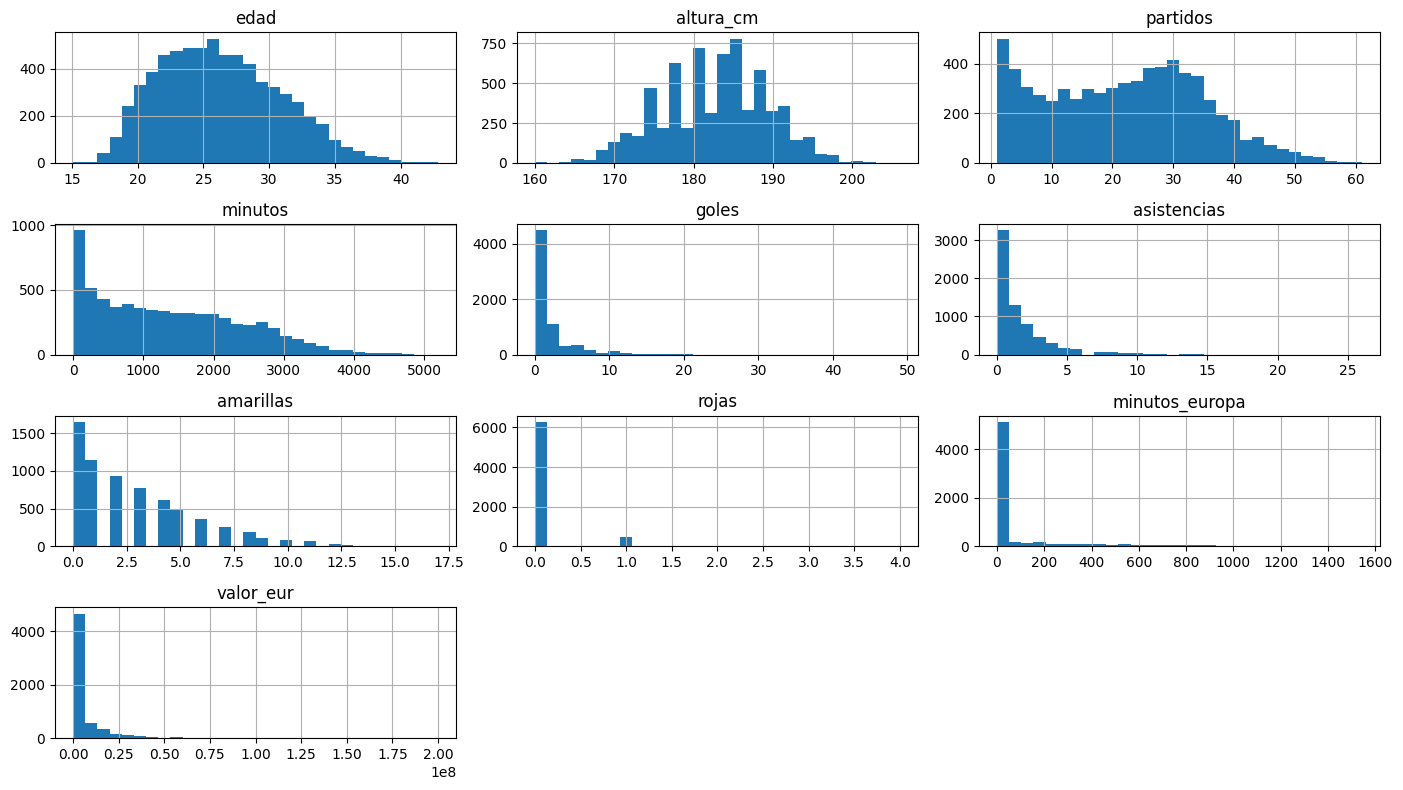

In [7]:
datos[numericas].hist(figsize=(14, 8), bins=30)
plt.tight_layout()
plt.show()

Edad y altura salen como campana. Goles, asistencias, rojas y minutos en Europa estan pegados al cero

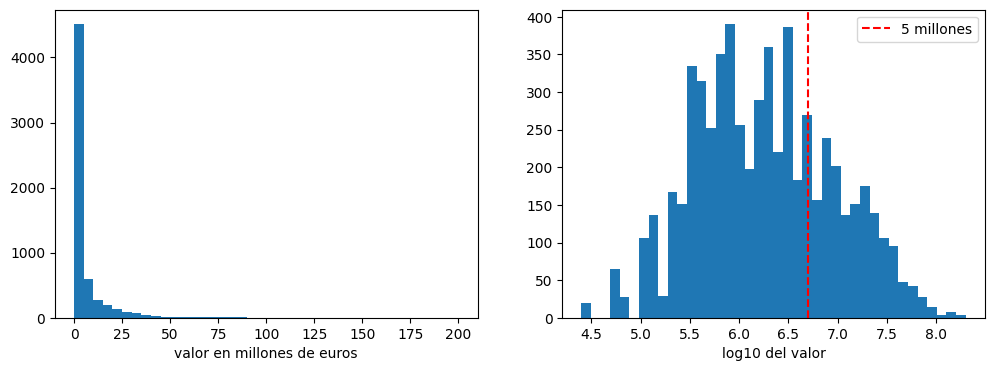

Mediana: 1500000.0
Media: 6355786.386915579
Jugadores de 5 millones o mas: 0.25931401537551746


In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].hist(datos["valor_eur"].dropna() / 1000000, bins=40)
ejes[0].set_xlabel("valor en millones de euros")

ejes[1].hist(np.log10(datos["valor_eur"].dropna()), bins=40)
ejes[1].axvline(np.log10(5000000), color="red", linestyle="--", label="5 millones")
ejes[1].set_xlabel("log10 del valor")
ejes[1].legend()

plt.show()

print("Mediana:", datos["valor_eur"].median())
print("Media:", datos["valor_eur"].mean())
print("Jugadores de 5 millones o mas:", (datos["valor_eur"] >= 5000000).mean())

La media es 6.36 millones y la mediana 1.5, unos pocos jugadores jalan el promedio. El 25.9 por ciento vale 5 millones o mas

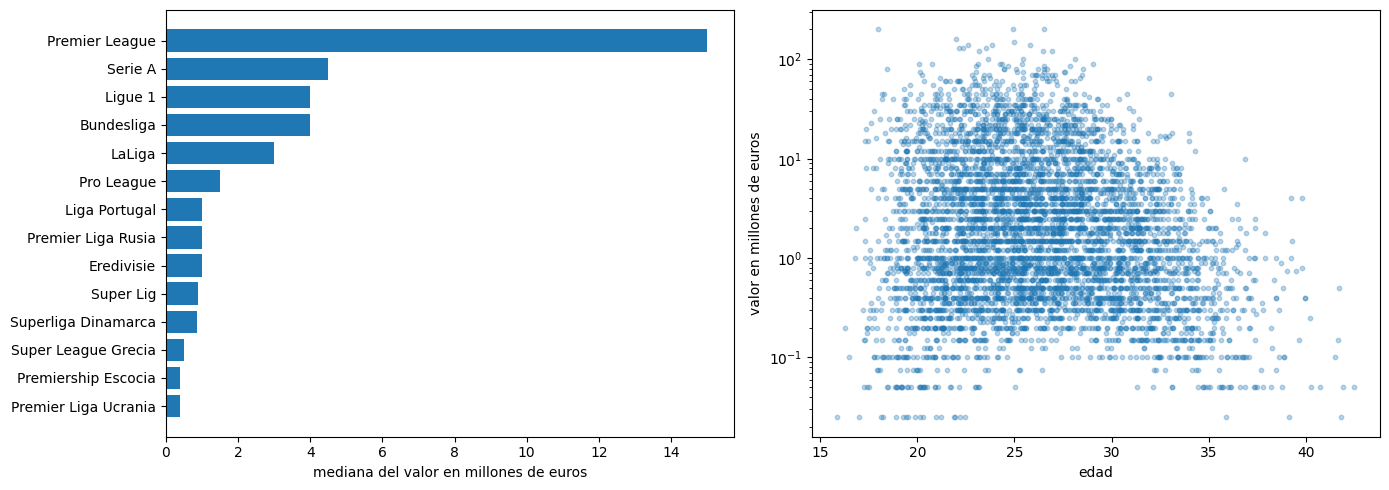

liga
Premier Liga Ucrania     0.40
Premiership Escocia      0.40
Super League Grecia      0.50
Superliga Dinamarca      0.85
Super Lig                0.90
Eredivisie               1.00
Premier Liga Rusia       1.00
Liga Portugal            1.00
Pro League               1.50
LaLiga                   3.00
Bundesliga               4.00
Ligue 1                  4.00
Serie A                  4.50
Premier League          15.00
Name: valor_eur, dtype: float64


In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

mediana = datos.groupby("liga")["valor_eur"].median().sort_values() / 1000000
ejes[0].barh(mediana.index, mediana)
ejes[0].set_xlabel("mediana del valor en millones de euros")

ejes[1].scatter(datos["edad"], datos["valor_eur"] / 1000000, alpha=0.3, s=10)
ejes[1].set_yscale("log")
ejes[1].set_xlabel("edad")
ejes[1].set_ylabel("valor en millones de euros")

plt.tight_layout()
plt.show()

print(mediana)

La Premier League tiene mediana de 15 millones contra 0.4 de Ucrania y Escocia. Los mas caros tienen entre 20 y 30 años

In [10]:
caros = datos[datos["valor_eur"].notna()].copy()
caros["caro"] = caros["valor_eur"] >= 5000000

print(pd.crosstab(caros["posicion"], caros["caro"], normalize="index").round(3))
print()

caros["log_valor"] = np.log10(caros["valor_eur"])
print(caros[numericas[:-1] + ["log_valor"]].corr()["log_valor"].round(3))

caro        False  True 
posicion                
Attack      0.687  0.313
Defender    0.724  0.276
Goalkeeper  0.787  0.213
Midfield    0.697  0.303
Missing     1.000  0.000

edad             -0.155
altura_cm         0.027
partidos          0.577
minutos           0.531
goles             0.395
asistencias       0.435
amarillas         0.327
rojas             0.059
minutos_europa    0.448
log_valor         1.000
Name: log_valor, dtype: float64


Lo que mas se relaciona con el valor es partidos con 0.577 y minutos con 0.531. La altura casi nada con 0.027

## ¿Qué información dan las muestras?

Cada muestra cuenta qué tipo de jugador es (edad, altura, posición, pie), en qué nivel compite (liga y minutos en torneos europeos) y qué tanto y qué tan bien jugó esa temporada (partidos, minutos, goles, asistencias, tarjetas). Junto con eso trae cuánto vale según el mercado después de esa temporada.

## ¿Qué se quiere analizar?

Se quiere saber si un jugador vale 5 millones de euros o más. Es una clasificación binaria: `caro = 1` si `valor_eur` es de al menos 5 millones y `caro = 0` si no. Se escogió ese umbral porque separa a cerca de una cuarta parte de los jugadores valuados, que son los que representan una inversión importante para la mayoría de los clubes de estas ligas, y porque deja clases desbalanceadas pero no extremas. También se quiere ver qué factores pesan más en esa decisión.

## Limpieza y transformación

**¿Qué variables se tienen que transformar para poder usarse en un modelo de regresión?** Las categóricas `posicion`, `pie` y `liga` no se pueden usar como texto. Varios conteos están sesgados a la derecha y todas las numéricas tienen escalas muy distintas. `valor_eur` tiene que convertirse en la clase a predecir.

**¿Qué transformaciones se van a usar?**

- `caro`: se crea a partir de `valor_eur`, que luego se deja fuera de los factores.
- `edad`: sale de `fecha_nacimiento`. Se agrega `edad2`, la edad al cuadrado, porque la relación con el valor no es lineal y la regresión logística solo puede verla así.
- $\ln(1 + x)$ en los conteos con sesgo mayor a 1: `goles`, `asistencias`, `amarillas`, `rojas` y `minutos_europa`. Se usa `log1p` y no `log` porque hay muchos ceros. `partidos` y `minutos` no se transforman porque casi no tienen sesgo.
- `StandardScaler` en todas las numéricas, porque los tres modelos dependen de la escala.
- `OneHotEncoder` en `posicion`, `pie` y `liga`, porque no tienen un orden.

Las transformaciones que no aprenden nada de los datos se hacen aquí. El escalamiento y la codificación van dentro del pipeline para ajustarse solo con los datos de entrenamiento de cada fold.

In [11]:
print("Antes:", datos.shape)

datos = datos.dropna(subset=["valor_eur", "fecha_nacimiento", "altura_cm"]).copy()
datos = datos[datos["posicion"] != "Missing"]
datos = datos[datos["minutos"] >= 90]

datos["pie"] = datos["pie"].fillna("desconocido")

print("Despues:", datos.shape)
print("Nulos en lo que se va a usar:", datos.drop(columns="sub_posicion").isna().sum().sum())

Antes: (6764, 18)
Despues: (5565, 18)
Nulos en lo que se va a usar: 0


Quedan 5565 jugadores. Se quitan los que no tienen valor, altura o fecha de nacimiento y los que jugaron menos de 90 minutos

In [12]:
conteos = ["partidos", "minutos", "goles", "asistencias", "amarillas", "rojas", "minutos_europa"]

print("Sesgo antes:")
print(datos[conteos].skew().round(2))

# log1p solo a las sesgadas
sesgadas = ["goles", "asistencias", "amarillas", "rojas", "minutos_europa"]

datos["caro"] = (datos["valor_eur"] >= 5000000).astype(int)
datos["edad2"] = datos["edad"] ** 2

for columna in sesgadas:
    datos[columna] = np.log1p(datos[columna])

print()
print("Sesgo despues:")
print(datos[sesgadas].skew().round(2))
print()
print(datos["caro"].value_counts())
print(datos["caro"].mean())

Sesgo antes:
partidos          0.08
minutos           0.47
goles             3.67
asistencias       2.56
amarillas         1.09
rojas             3.75
minutos_europa    2.25
dtype: float64

Sesgo despues:
goles             0.79
asistencias       0.61
amarillas        -0.24
rojas             3.26
minutos_europa    0.93
dtype: float64

caro
0    3839
1    1726
Name: count, dtype: int64
0.3101527403414196


Partidos y minutos casi no tienen sesgo y se quedan igual, las otras cinco bajan. El 31 por ciento son caros

## ¿Qué resultado se podría encontrar al realizar una regresión?

Por lo visto en el EDA se espera que la liga y la edad sean los factores más fuertes: un jugador joven en una liga grande debería tener mucha más probabilidad de ser caro. También se espera que los minutos y los minutos en Europa empujen hacia arriba, porque indican que el jugador es titular en un equipo fuerte. Los goles y las asistencias deberían ayudar, pero menos, porque su importancia depende de la posición. Como varias de estas relaciones no son lineales, la SVM y el perceptrón deberían superar a la regresión logística, aunque no por mucho.

# Modelo propuesto

Se proponen tres modelos para predecir `caro`, con los mismos 10 factores numéricos y 3 categóricos, y cada uno con sus hiperparámetros optimizados con procesos gaussianos:

| Modelo | Clase en `sklearn` | Hiperparámetros a optimizar | Rango |
|:---|:---|:---|:---|
| 1. Regresión logística con regularización | `LogisticRegression` | $C$ | $10^{-4}$ a $10^{3}$ |
| 2. Máquina de vectores de soporte, kernel RBF | `SVC` | $C$ y $\gamma$ | $10^{-2}$ a $10^{4}$ y $10^{-4}$ a $10^{0}$ |
| 3. Perceptrón multicapa de dos capas ocultas | `MLPClassifier` | neuronas por capa y `alpha` | 10 a 100, 5 a 50 y $10^{-5}$ a $10^{1}$ |

**Métrico elegido: AUC.** No depende de un umbral, así que mide qué tan bien ordena el modelo a los jugadores, y no se infla con el desbalance: un modelo que dice que nadie es caro tendría un accuracy alto pero un AUC de 0.5.

Los rangos de $C$, $\gamma$ y `alpha` se buscan en escala logarítmica, porque lo que importa es el orden de magnitud. Con 30 evaluaciones por modelo la búsqueda es mucho más barata que probar todas las combinaciones.

# Pipeline

El flujo sigue el esquema visto en clase. Del dataset se hace el EDA y de ahí salen $X$ y $y$. $X$ pasa por la ingeniería de características para obtener $X^*$, y con $X^*$, $y$ y los hiperparámetros $H$ se entrena el modelo. Con los datos nuevos, que aquí son los de prueba, se aplica la misma ingeniería ya ajustada, se predice y se evalúa. Además está el ciclo de optimización: el proceso gaussiano propone un $H$, el K-Fold lo califica con el AUC y ese resultado regresa al proceso gaussiano. Todo lo que va de la ingeniería de características al ajuste vive dentro de un `Pipeline` de `sklearn`.

![pipeline](pipeline.png)

## Separar en train y test y armar el preprocesamiento

In [13]:
numerical_cols = ["edad", "edad2", "altura_cm", "partidos", "minutos", "goles", "asistencias", "amarillas", "rojas", "minutos_europa"]
categorical_cols = ["posicion", "pie", "liga"]

X = datos[numerical_cols + categorical_cols]
y = datos["caro"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ],
    remainder="drop",
)

kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
kf10 = KFold(n_splits=10, shuffle=True, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(3895, 13) (1670, 13)
0.3155327342747112 0.29760479041916166


3895 para entrenar y 1670 para prueba. El K-Fold de 5 es para optimizar y el de 10 para comparar

## Funciones para evaluar y optimizar

In [14]:
def auc_kfold(pipeline, kf, es_svc=False):
    aucs = []
    for train_idx, test_idx in kf.split(X_train):
        pipeline.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        if es_svc:
            score = pipeline.decision_function(X_train.iloc[test_idx])
        else:
            score = pipeline.predict_proba(X_train.iloc[test_idx])[:, 1]
        aucs.append(roc_auc_score(y_train.iloc[test_idx], score))
    return np.array(aucs)

def optimizar(objetivo, H_new, kernel, n_ini=5, n_iter=25):
    np.random.seed(42)
    probados = list(np.random.choice(len(H_new), n_ini, replace=False))
    auc = [objetivo(H_new[i]) for i in probados]

    for i in range(n_iter):
        gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, normalize_y=True, alpha=1e-6)
        gp.fit(H_new[probados], auc)
        y_pred, desv = gp.predict(H_new, return_std=True)

        limite = y_pred + 2*desv
        limite[probados] = -np.inf  # no repetir

        siguiente = np.argmax(limite)
        probados.append(siguiente)
        auc.append(objetivo(H_new[siguiente]))

    gp.fit(H_new[probados], auc)
    return H_new[probados], np.array(auc), gp

optimizar hace lo mismo que en la actividad 9, empieza con 5 combinaciones al azar y prueba 25 mas con prediccion + 2 desviaciones

# **MODELO 1:** Regresión logística con regularización

In [15]:
def crear_logistica(h):
    return Pipeline(steps=[("preprocessor", preprocessor), ("modelo", LogisticRegression(C=10**h[0], max_iter=2000))])

def objetivo_logistica(h):
    return auc_kfold(crear_logistica(h), kf5).mean()


H_logistica = np.linspace(-4, 3, 141).reshape([-1, 1])

probados_1, auc_1, gp_1 = optimizar(objetivo_logistica, H_logistica, 1.0 * RBF(length_scale=1.0))

mejor_1 = probados_1[np.argmax(auc_1)]

print("Mejor C:", 10**mejor_1[0])
print("AUC:", auc_1.max())

Mejor C: 501.18723362727246
AUC: 0.9317536529886814


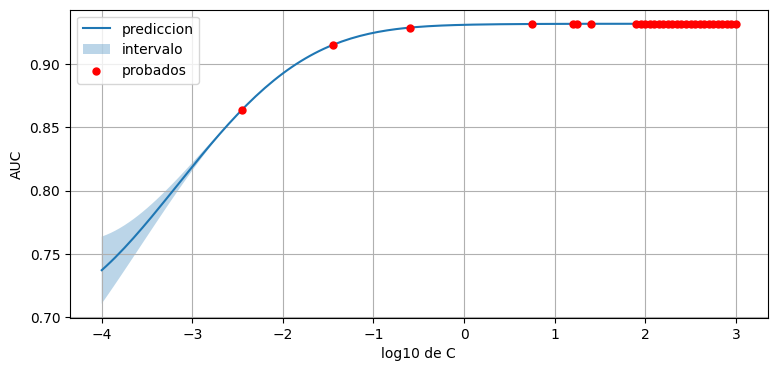

In [16]:
y_pred, desv = gp_1.predict(H_logistica, return_std=True)

plt.figure(figsize=(9, 4))
plt.plot(H_logistica, y_pred, label="prediccion")
plt.fill_between(H_logistica.ravel(), y_pred - 2*desv, y_pred + 2*desv, alpha=0.3, label="intervalo")
plt.scatter(probados_1, auc_1, s=25, c="r", zorder=3, label="probados")
plt.xlabel("log10 de C")
plt.ylabel("AUC")
plt.grid()
plt.legend()
plt.show()

El mejor C salio 501 con 0.9318 de AUC. Desde C = 1 la curva se queda plana, casi no hace falta regularizar

# **MODELO 2:** Máquina de vectores de soporte con kernel RBF

In [17]:
def crear_svc(h):
    return Pipeline(steps=[("preprocessor", preprocessor), ("modelo", SVC(kernel="rbf", C=10**h[0], gamma=10**h[1]))])

def objetivo_svc(h):
    return auc_kfold(crear_svc(h), kf5, es_svc=True).mean()


H_svc = []
for c in np.arange(-2, 4.01, 0.25):
    for g in np.arange(-4, 0.01, 0.2):
        H_svc.append([c, g])

H_svc = np.array(H_svc)
print(len(H_svc))

probados_2, auc_2, gp_2 = optimizar(objetivo_svc, H_svc, 1.0 * RBF(length_scale=[1.0, 1.0]))

mejor_2 = probados_2[np.argmax(auc_2)]

print("Mejor C:", 10**mejor_2[0], " gamma:", 10**mejor_2[1])
print("AUC:", auc_2.max())

525


Mejor C: 10000.0  gamma: 0.0006309573444801943
AUC: 0.9362429504226212


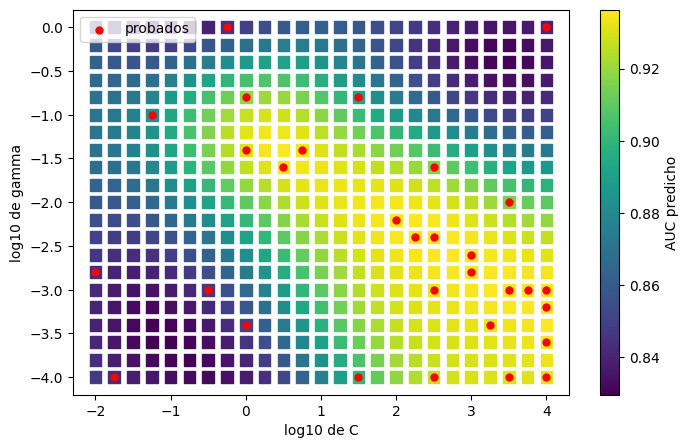

In [18]:
y_pred = gp_2.predict(H_svc)

plt.figure(figsize=(8, 5))
plt.scatter(H_svc[:, 0], H_svc[:, 1], c=y_pred, s=70, marker="s")
plt.colorbar(label="AUC predicho")
plt.scatter(probados_2[:, 0], probados_2[:, 1], s=25, c="r", label="probados")
plt.xlabel("log10 de C")
plt.ylabel("log10 de gamma")
plt.legend()
plt.show()

La mejor fue C = 10000 y gamma = 0.00063 con 0.9362 de AUC. C quedo en la orilla pero al ampliar el rango el AUC casi no cambio

# **MODELO 3:** Perceptrón multicapa

In [19]:
def crear_mlp(h):
    red = MLPClassifier(hidden_layer_sizes=(int(h[0]), int(h[1])), alpha=10**h[2], early_stopping=True, max_iter=500, random_state=42)
    return Pipeline(steps=[("preprocessor", preprocessor), ("modelo", red)])

def objetivo_mlp(h):
    return auc_kfold(crear_mlp(h), kf5).mean()


H_mlp = []
for c1 in range(10, 101, 10):
    for c2 in range(5, 51, 5):
        for a in np.arange(-5, 1.01, 0.5):
            H_mlp.append([c1, c2, a])

H_mlp = np.array(H_mlp)
print(len(H_mlp))

probados_3, auc_3, gp_3 = optimizar(objetivo_mlp, H_mlp, 1.0 * RBF(length_scale=[30.0, 15.0, 2.0]))

mejor_3 = probados_3[np.argmax(auc_3)]

print("Mejores capas:", int(mejor_3[0]), int(mejor_3[1]), " alpha:", 10**mejor_3[2])
print("AUC:", auc_3.max())

1300


Mejores capas: 100 30  alpha: 1e-05
AUC: 0.933720880846215


La mejor red fue de 100 y 30 neuronas con 0.9337 de AUC

# Ajuste de modelos y comparación del AUC

In [20]:
modelos = {
    "Logistica default": Pipeline(steps=[("preprocessor", preprocessor), ("modelo", LogisticRegression(max_iter=2000))]),
    "Logistica optimizada": crear_logistica(mejor_1),
    "SVC default": Pipeline(steps=[("preprocessor", preprocessor), ("modelo", SVC(kernel="rbf"))]),
    "SVC optimizado": crear_svc(mejor_2),
    "MLP default": Pipeline(steps=[("preprocessor", preprocessor), ("modelo", MLPClassifier(max_iter=500, random_state=42))]),
    "MLP optimizado": crear_mlp(mejor_3),
}

resultados = []

for nombre, modelo in modelos.items():
    aucs = auc_kfold(modelo, kf10, es_svc=nombre.startswith("SVC"))
    resultados.append({"modelo": nombre, "AUC media": aucs.mean(), "AUC desviacion": aucs.std()})

resultados = pd.DataFrame(resultados).set_index("modelo")
resultados.round(4)

,AUC media,AUC desviacion
modelo,,
Logistica default,0.9306,0.0125
Logistica optimizada,0.9317,0.0123
SVC default,0.9301,0.0097
SVC optimizado,0.9371,0.0110
MLP default,0.9235,0.0103
MLP optimizado,0.9322,0.0119


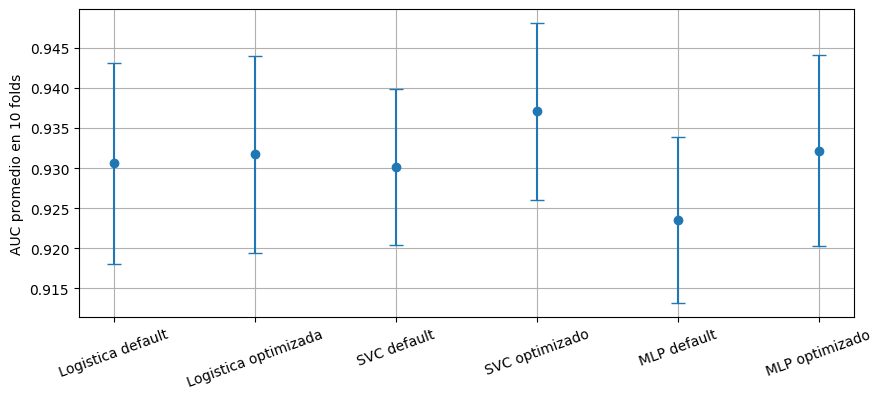

In [21]:
plt.figure(figsize=(10, 4))
plt.errorbar(resultados.index, resultados["AUC media"], yerr=resultados["AUC desviacion"], fmt="o", capsize=5)
plt.ylabel("AUC promedio en 10 folds")
plt.xticks(rotation=20)
plt.grid()
plt.show()

El SVC optimizado es el mejor con 0.9371, pero la desviacion es como de 0.011 y es mas grande que la diferencia entre modelos, gana por poquito

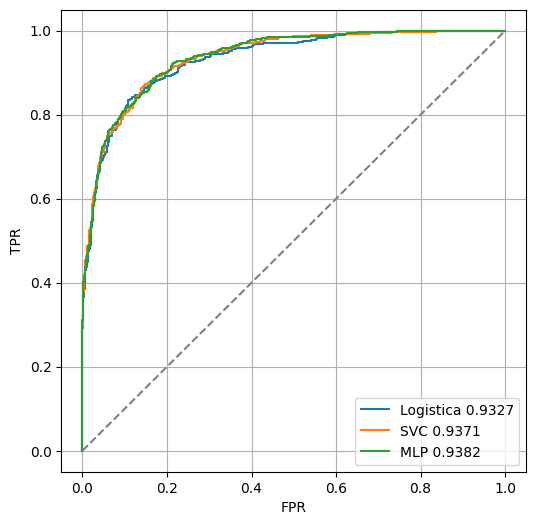

,AUC,accuracy,recall,precision,F1
modelo,,,,,
Logistica,0.9327,0.8796,0.7485,0.8304,0.7873
SVC,0.9371,0.8772,0.7586,0.8160,0.7862
MLP,0.9382,0.8772,0.7867,0.7980,0.7923


In [22]:
finales = {"Logistica": modelos["Logistica optimizada"], "SVC": modelos["SVC optimizado"], "MLP": modelos["MLP optimizado"]}

prueba = []
plt.figure(figsize=(6, 6))

for nombre, modelo in finales.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    if nombre == "SVC":
        score = modelo.decision_function(X_test)
    else:
        score = modelo.predict_proba(X_test)[:, 1]

    fpr, tpr, umbrales = roc_curve(y_test, score)
    plt.plot(fpr, tpr, label=nombre + " " + str(round(roc_auc_score(y_test, score), 4)))

    prueba.append({"modelo": nombre,
                   "AUC": roc_auc_score(y_test, score),
                   "accuracy": accuracy_score(y_test, y_pred),
                   "recall": recall_score(y_test, y_pred),
                   "precision": precision_score(y_test, y_pred),
                   "F1": f1_score(y_test, y_pred)})

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.grid()
plt.show()

prueba = pd.DataFrame(prueba).set_index("modelo")
prueba.round(4)

In [23]:
# renglones lo real, columnas lo predicho

for nombre, modelo in finales.items():
    print(nombre)
    print(confusion_matrix(y_test, modelo.predict(X_test)))

Logistica
[[1097   76]
 [ 125  372]]
SVC
[[1088   85]
 [ 120  377]]
MLP
[[1074   99]
 [ 106  391]]


En prueba salen casi igual que en validacion, no hay sobreajuste. El MLP detecta 391 de 497 caros y el SVC 377

## ¿Qué factores pesan más?

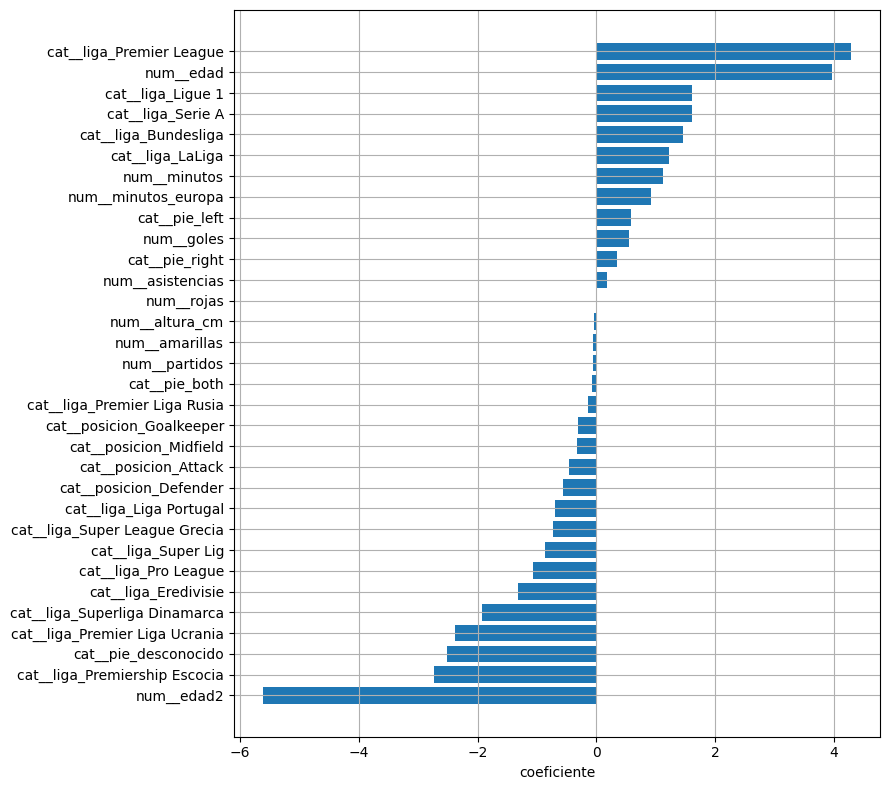

num__edad2                       -5.613
cat__liga_Premiership Escocia    -2.743
cat__pie_desconocido             -2.522
cat__liga_Premier Liga Ucrania   -2.376
cat__liga_Superliga Dinamarca    -1.923
cat__liga_Eredivisie             -1.327
cat__liga_Pro League             -1.071
cat__liga_Super Lig              -0.867
cat__liga_Super League Grecia    -0.726
cat__liga_Liga Portugal          -0.699
cat__posicion_Defender           -0.563
cat__posicion_Attack             -0.466
cat__posicion_Midfield           -0.333
cat__posicion_Goalkeeper         -0.313
cat__liga_Premier Liga Rusia     -0.134
cat__pie_both                    -0.080
num__partidos                    -0.062
num__amarillas                   -0.057
num__altura_cm                   -0.044
num__rojas                        0.008
num__asistencias                  0.186
cat__pie_right                    0.348
num__goles                        0.546
cat__pie_left                     0.579
num__minutos_europa               0.914


In [24]:
logistica = finales["Logistica"]

nombres = logistica.named_steps["preprocessor"].get_feature_names_out()
coeficientes = pd.Series(logistica.named_steps["modelo"].coef_[0], index=nombres).sort_values()

plt.figure(figsize=(9, 8))
plt.barh(coeficientes.index, coeficientes)
plt.xlabel("coeficiente")
plt.grid()
plt.tight_layout()
plt.show()

coeficientes.round(3)

In [25]:
# porcentaje de caros por edad, de 5 en 5 años

grupos = (datos["edad"] // 5 * 5).astype(int)

datos.groupby(grupos)["caro"].mean().round(3)

edad
15    0.452
20    0.377
25    0.339
30    0.149
35    0.012
40    0.000
Name: caro, dtype: float64

Lo que mas pesa es la liga, Premier League 4.28 contra Escocia -2.74. En edad, de 20 a 24 años hay 37.7 por ciento de caros y de 30 a 34 solo 14.9. Minutos y minutos en Europa pesan mas que goles y asistencias

# Conclusiones

El objetivo general era predecir si un futbolista vale mucho dinero a partir de su perfil y su rendimiento. Sí se pudo: el mejor modelo, la SVM con kernel RBF, sacó un AUC de 0.9371 en validación cruzada y también en prueba, sin usar el club ni el valor anterior del jugador.

**Sobre el dataset (objetivo 1).** De 6764 jugadores de 14 ligas quedaron 5565 después de la limpieza, y el 31 % vale 5 millones de euros o más. Cinco conteos tenían sesgo mayor a 1 y se transformaron con `log1p`. En `rojas` casi no ayudó porque casi todos tienen cero.

**Sobre el pipeline (objetivo 2).** El escalamiento y la codificación se hicieron dentro del `Pipeline`, con los datos de entrenamiento de cada fold. El AUC de prueba salió muy parecido al de validación en los tres modelos, así que no hubo sobreajuste.

**Sobre la optimización (objetivo 3).** Con 30 evaluaciones por modelo se encontraron buenos hiperparámetros, contra 525 y 1300 combinaciones posibles en la SVM y el perceptrón. El AUC subió 0.0087 en el perceptrón y 0.0070 en la SVM. En la regresión logística solo subió 0.0011 porque casi no necesita regularización. En la SVM el mejor $C$ quedó en la orilla del rango, pero al ampliarlo el AUC casi no cambió.

**Sobre la comparación de modelos (objetivo 4).** En 10 folds la SVM sacó 0.9371, el perceptrón 0.9322 y la regresión logística 0.9317, con desviaciones de 0.0110 a 0.0123. La diferencia es menor que la desviación, y en prueba el perceptrón quedó un poco arriba de la SVM, así que no hay un ganador claro. La regresión logística, que es el modelo más simple, quedó muy cerca.

**Sobre los factores (objetivo 5).** Lo que más pesa es la liga: la Premier League tiene un coeficiente de 4.28 y Escocia de -2.74. La edad también pesa: de 20 a 24 años el 37.7 % son caros y de 30 a 34 solo el 14.9 %. Los minutos y los minutos en Europa pesan más que los goles y las asistencias. El modelo no conoce lesiones ni contratos, y el valor de mercado es una estimación de Transfermarkt, no un precio real. También es una sola temporada de 14 ligas europeas, así que no se puede generalizar a otras ligas como la Liga MX.

# Referencias

Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. *Pattern Recognition, 30*(7), 1145-1159. https://doi.org/10.1016/S0031-3203(96)00142-2

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273-297. https://doi.org/10.1007/BF00994018

dcaribou. (2026). *transfermarkt-datasets* [Data set]. GitHub. https://github.com/dcaribou/transfermarkt-datasets

Herm, S., Callsen-Bracker, H.-M., & Kreis, H. (2014). When the crowd evaluates soccer players' market values: Accuracy and evaluation attributes of an online community. *Sport Management Review, 17*(4), 484-492. https://doi.org/10.1016/j.smr.2013.12.006

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Müller, O., Simons, A., & Weinmann, M. (2017). Beyond crowd judgments: Data-driven estimation of market value in association football. *European Journal of Operational Research, 263*(2), 611-624. https://doi.org/10.1016/j.ejor.2017.05.005

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press.

Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*, 533-536. https://doi.org/10.1038/323533a0

Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. *Advances in Neural Information Processing Systems, 25*.